# Wastewater pipe blockages: exploratory analysis (baseline A7)

Population: in-service, council-owned gravity sewer pipes ≥ 1 m (see `reports/profile_summary.md`).
Target: recorded blockages per pipe (**all time, undated**). Exposure: pipe length, so rates are **per km of pipe**.
Everything here is association, not causation.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2

ROOT = Path.cwd()
while not (ROOT / "ccc_data").exists():
    ROOT = ROOT.parent
df = gpd.read_parquet(ROOT / "data/clean/pipe_blockages/model_table.parquet")
FIG = ROOT / "projects/pipe_blockages/outputs/figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
ACCENT = "#1f6f5c"

def rate_table(d, by):
    g = d.groupby(by, observed=True).agg(blockages=("blockages", "sum"), km=("length_m", lambda s: s.sum() / 1000), pipes=("id", "size"))
    lo = chi2.ppf(0.025, 2 * g.blockages) / 2; hi = chi2.ppf(0.975, 2 * (g.blockages + 1)) / 2
    g["per_km"] = g.blockages / g.km; g["lo"] = np.nan_to_num(lo) / g.km; g["hi"] = hi / g.km
    return g

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=110); plt.show()

print(f"{len(df):,} pipes, {(df.blockages > 0).sum():,} blocked, {df.blockages.sum():,} blockages, {df.length_m.sum() / 1000:,.0f} km")

32,438 pipes, 1,320 blocked, 1,860 blockages, 1,646 km


## 1. Blockage rate by pipe material

,blockages,km,pipes,per_km,lo,hi
material,,,,,,
Metal,45,8.493,462,5.298,3.865,7.090
Earthenware,432,231.816,4160,1.864,1.692,2.048
Asbestos cement,175,103.317,2225,1.694,1.452,1.964
Concrete,720,558.803,9822,1.288,1.196,1.386
Plastic,488,738.206,15674,0.661,0.604,0.722
Other,0,4.693,80,0.000,0.000,0.786
Unknown,0,0.195,15,0.000,0.000,18.966


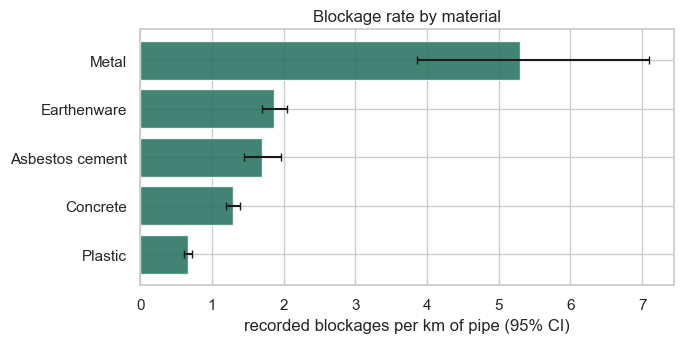

In [2]:
r = rate_table(df, "material").sort_values("per_km", ascending=False); display(r.round(3))
r = r[r.km >= 5]  # groups under 5 km of pipe are too small to chart
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(r.index, r.per_km, xerr=[r.per_km - r.lo, r.hi - r.per_km], color=ACCENT, alpha=.85, capsize=3)
ax.invert_yaxis(); ax.set_xlabel("recorded blockages per km of pipe (95% CI)"); ax.set_title("Blockage rate by material")
save(fig, "rate_by_material")

**What this tells us:** Material matters a lot. Earthenware (1.86 blockages per km) and asbestos cement (1.69) block at about 2.5–2.8× the rate of plastic (0.66); concrete sits between (1.29). Metal looks highest (5.3/km) but is only 8.5 km of pipe (mostly short sections at structures), so it is noisy. Groups under 5 km of pipe are left out of the chart. **Use:** material is the first thing to look at when choosing pipes to inspect.

## 2. Rate by pipe age and material

material,Asbestos cement,Concrete,Earthenware,Plastic
age_band,,,,
<20,0.000,0.000,0.000,0.198
20–40,2.840,1.106,1.524,1.233
40–60,1.667,0.992,3.613,4.359
60–80,0.783,1.428,3.253,6.324
80+,5.010,1.357,1.685,9.494


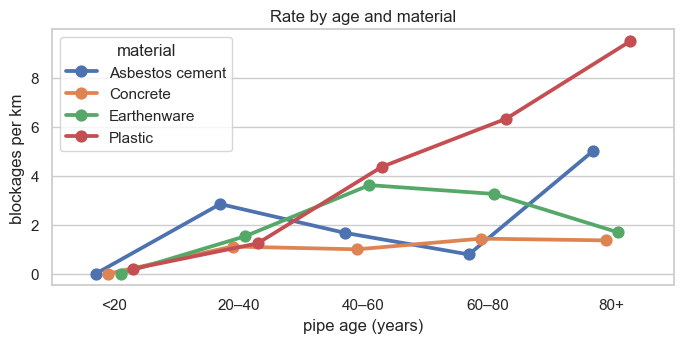

In [3]:
d = df.assign(age_band=pd.cut(df.age_years, [0, 20, 40, 60, 80, 200], labels=["<20", "20–40", "40–60", "60–80", "80+"]))
main = d[d.material.isin(["Plastic", "Concrete", "Earthenware", "Asbestos cement"])]
r = rate_table(main, ["age_band", "material"]).reset_index(); display(r.pivot(index="age_band", columns="material", values="per_km").round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.pointplot(data=r, x="age_band", y="per_km", hue="material", ax=ax, dodge=.3)
ax.set_xlabel("pipe age (years)"); ax.set_ylabel("blockages per km"); ax.set_title("Rate by age and material")
save(fig, "rate_by_age_material")

**What this tells us:** For the old pipe materials the rate rises with age, as expected. But 'plastic' pipes recorded as 60–80+ years old block at 6–9 per km, and plastic sewers did not exist then: these are almost certainly old pipes relined or replaced in plastic that kept their original commission date. So **age is unreliable for renewed pipes**, and 'old plastic' is really a marker of a pipe that already had problems.

## 3. Rate by number of trees within 5 m

,blockages,km,pipes,per_km,lo,hi
trees,,,,,,
0,1411,1162.072,24551,1.214,1.152,1.279
1,170,152.358,2921,1.116,0.954,1.297
2,77,102.594,1749,0.751,0.592,0.938
3–5,138,153.605,2285,0.898,0.755,1.061
6+,64,74.894,932,0.855,0.658,1.091


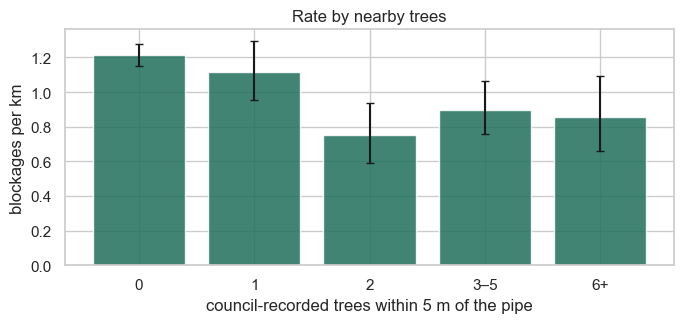

In [4]:
d = df.assign(trees=pd.cut(df.trees_5m, [-1, 0, 1, 2, 5, 10_000], labels=["0", "1", "2", "3–5", "6+"]))
r = rate_table(d, "trees"); display(r.round(3))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(r.index.astype(str), r.per_km, yerr=[r.per_km - r.lo, r.hi - r.per_km], color=ACCENT, alpha=.85, capsize=3)
ax.set_xlabel("council-recorded trees within 5 m of the pipe"); ax.set_ylabel("blockages per km"); ax.set_title("Rate by nearby trees")
save(fig, "rate_by_trees")

**What this tells us:** Surprise: pipes with **no** council-recorded trees within 5 m have the *highest* rate (1.21/km); pipes with 2+ trees sit at 0.75–0.90. This is raw and confounded (street trees cluster on newer, wider streets with plastic pipes), and council data only records street and park trees. The backyard trees most likely to send roots into older sewers are not in the data. **Do not read this as 'trees prevent blockages'.**

## 4. Trees × material: do trees matter more for earthenware?

material,Concrete,Earthenware,Plastic
trees,,,
0,1.304,1.981,0.738
1,1.804,1.790,0.510
2,0.999,1.145,0.428
3–5,1.047,1.751,0.528
6+,0.932,1.200,0.489


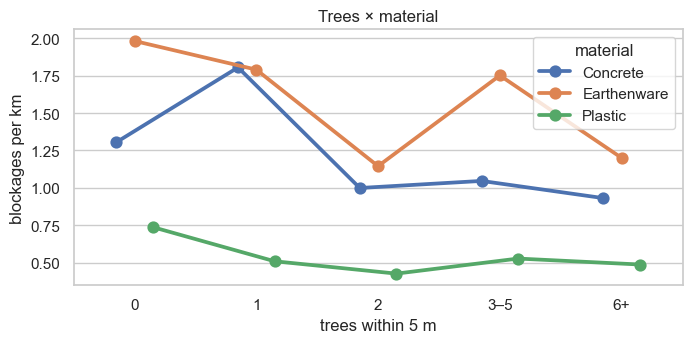

In [5]:
d = d[d.material.isin(["Plastic", "Earthenware", "Concrete"])]
r = rate_table(d, ["material", "trees"]).reset_index(); display(r.pivot(index="trees", columns="material", values="per_km").round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.pointplot(data=r, x="trees", y="per_km", hue="material", ax=ax, dodge=.3)
ax.set_xlabel("trees within 5 m"); ax.set_ylabel("blockages per km"); ax.set_title("Trees × material")
save(fig, "rate_by_trees_material")

**What this tells us:** The same pattern holds inside each material: even for earthenware, pipes with no recorded trees nearby block more (1.98/km) than those with 6+ (1.20/km). So the tree pattern is not just a material mix-up. The model in Task 4 checks whether it survives controls for age, size, depth and location.

## 5. Root-aggressive genera vs other trees

,blockages,km,pipes,per_km,lo,hi
grp,,,,,,
no trees within 10 m,998,734.657,16738,1.358,1.275,1.445
other trees only,365,365.162,6686,1.000,0.900,1.108
root-aggressive genus within 10 m,497,545.704,9014,0.911,0.832,0.994


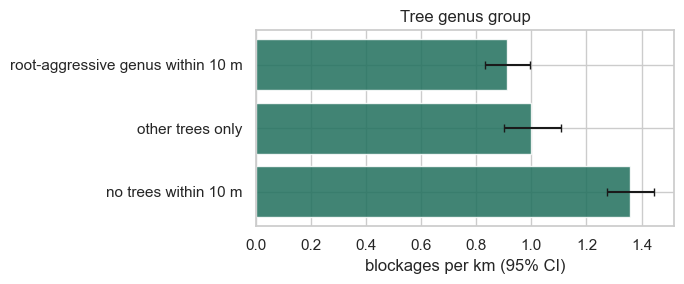

In [6]:
grp = np.select([df.aggressive_trees_10m > 0, df.trees_10m > 0], ["root-aggressive genus within 10 m", "other trees only"], "no trees within 10 m")
r = rate_table(df.assign(grp=grp), "grp"); display(r.round(3))
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(r.index, r.per_km, xerr=[r.per_km - r.lo, r.hi - r.per_km], color=ACCENT, alpha=.85, capsize=3)
ax.set_xlabel("blockages per km (95% CI)"); ax.set_title("Tree genus group")
save(fig, "rate_by_genus_group")

**What this tells us:** Pipes near root-aggressive genera (willow, poplar, gum, oak, ash, maple, elm, plane, birch, liquidambar) do *not* block more than pipes near other recorded trees (0.91 vs 1.00/km); both are below 'no recorded trees' (1.36/km). There is no sign, in council-recorded trees, that genus matters.

## 6. Where are the most-blocked pipes?

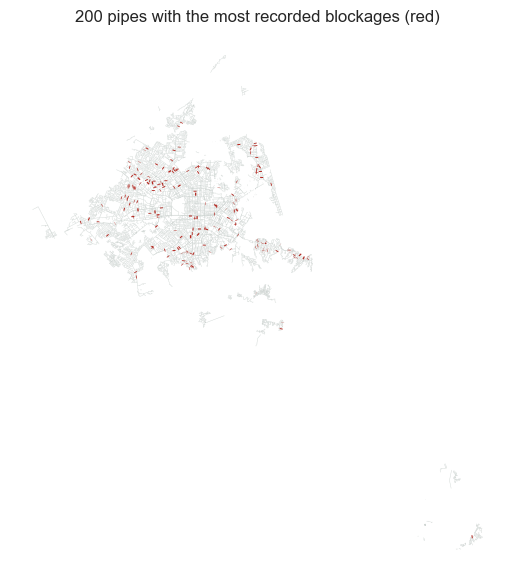

,street,material,age_years,trees_5m,blockages
17459,Desi Place,Asbestos cement,41.84,0,8
12301,MacKenzie Avenue,Concrete,58.84,5,8
4267,Wentworth Street,Concrete,61.84,0,8
15338,Main Road,Plastic,96.84,0,8
330,Scarborough Road,Concrete,80.84,0,7
3390,,Concrete,61.84,0,7
17535,,Earthenware,81.84,0,7
2993,Memorial Avenue,Concrete,67.84,1,7
4063,Cranbrook Avenue,Concrete,68.84,0,7
17497,Taunton Green,Plastic,24.84,0,6


In [7]:
top = df.sort_values("blockages", ascending=False).head(200).to_crs(4326)
fig, ax = plt.subplots(figsize=(7, 6))
df.to_crs(4326).plot(ax=ax, color="#cfd6d3", linewidth=.3)
top.plot(ax=ax, color="#b3261e", linewidth=2.2)
ax.set_axis_off(); ax.set_title("200 pipes with the most recorded blockages (red)")
save(fig, "map_top200")
display(top[["street", "material", "age_years", "trees_5m", "blockages"]].head(15))

**What this tells us:** The most-blocked pipes are spread across the older suburbs rather than one cluster, and most have zero or one recorded tree within 5 m. Concrete pipes 60–80 years old dominate the top 15.

## 7. How the numeric features relate

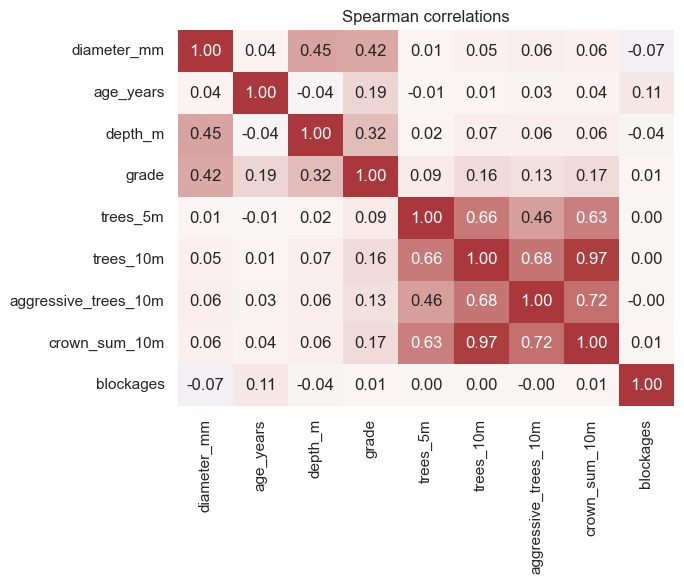

In [8]:
num = ["diameter_mm", "age_years", "depth_m", "grade", "trees_5m", "trees_10m", "aggressive_trees_10m", "crown_sum_10m", "blockages"]
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(df[num].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar=False)
ax.set_title("Spearman correlations"); fig.tight_layout(); plt.show()

**What this tells us:** No single numeric feature is strongly correlated with blockages on its own (all |ρ| small), and the tree measures are strongly correlated with each other. That argues for a multivariable model with a length offset rather than reading any one chart.

## 8. Relined pipes (confounded)

In [9]:
r = rate_table(df, "relined"); display(r.round(3))

,blockages,km,pipes,per_km,lo,hi
relined,,,,,,
False,1597,1476.203,29884,1.082,1.029,1.136
True,263,169.320,2554,1.553,1.371,1.753


**What this tells us:** Relined pipes have a *higher* recorded rate (1.55 vs 1.08/km). That is reverse causation: pipes get relined because they blocked, and the counts include blockages from before relining. Relining is kept as a control in the explanatory model but excluded from the risk score.

## Modelling hypotheses

- **H1 (material): supported.** Earthenware ≈ 2.8× and asbestos cement ≈ 2.6× plastic per km. Keep material as the main driver.
- **H2 (trees within 5 m raise the rate): not supported in the raw data;** the raw association is negative. Test it in the negative-binomial model with controls, and report whatever it shows, including 'no evidence of a tree effect in council-recorded trees'.
- **H3 (root-aggressive genera worse): not supported** in the raw data. Keep `aggressive_trees_10m` in the model to test it formally.
- **H4 (older/shallower worse): partly.** Age raises the rate for old materials, but recorded age is unreliable for renewed pipes. Keep age with its missing flag and interpret it with material.
- **H5 (relining confounded): confirmed.** Use it as a control only, never as a predictor of future risk.
- **Spatial pattern:** blockages cluster in older suburbs, so validation must be spatially grouped (1 km cells) to avoid optimistic scores.